In [1]:
import xarray as xr
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline
import cartopy.crs as ccrs
import sys
sys.path.insert(0,'/users/emmomp/Python/ECCOv4-py')
import ecco_v4_py as ecco
sys.path.insert(0,'/users/emmomp/Python')
import xadjoint as xad
import utils as ut
import calendar
from inputs import DATA_DIR, GRIDDIR, EXPDIR, eyears, CONTR_DIR, mthi, ecco_grid, ecco_convs_2d, EV_DIR, FCNAME
import warnings
warnings.filterwarnings('ignore')

In [2]:
mean_ssh=xr.open_dataarray(f'{DATA_DIR}/eccov4_meanssh.nc')

In [3]:
ds_plot_contr=[]
for year in eyears:
    ds_plot=xr.open_mfdataset(f'{CONTR_DIR}/{year}/ecco_2dconvs_{year}*nc',concat_dim='lag_range',combine='nested')
    ds_plot['exp']=[str(x) for x in ds_plot.exp.data]
    ds_plot_contr.append(ds_plot.assign_coords({'eyear':year}).swap_dims({'exp':'month'}).drop_vars('exp'))
ds_plot_contr=xr.concat(ds_plot_contr,'eyear',coords='minimal')
ds_plot_contr['wind_OCE']=ds_plot_contr['adxx_tauuXoceTAUU']+ds_plot_contr['adxx_tauvXoceTAUV']
ds_plot_contr=ds_plot_contr.stack({'ym':['month','year']}).sortby('dates')

In [4]:
ev_2d_all=[]
for year in eyears:
    ev_2d=[]
    for var in ecco_convs_2d:
        foo=xr.open_dataarray(f'{EV_DIR}/{year}/horflux_fw_denm_fullEV2d_{var}_{year}.nc')
        foo.name=var
        ev_2d.append(foo)
    ev_2d=xr.merge(ev_2d).assign_coords({'eyear':year})
    ev_2d_all.append(ev_2d)
ev_2d=xr.concat(ev_2d_all,'eyear',coords='minimal')
ev_2d['wind_OCE']=ev_2d['adxx_tauuXoceTAUU']+ev_2d['adxx_tauvXoceTAUV']

In [5]:
xmin,xmax,ymin,ymax=(-2266791.253073855,
 3358349.2597455736,
 -2166791.253073855,
 3458349.2597455736)
proj_dict={'projection_type':'ortho','user_lon_0':-45,'user_lat_0':70}
my_projn = ccrs.Orthographic(central_longitude=-45,central_latitude=70)
[section_pt1,section_pt2]=ecco.get_section_endpoints('Denmark Strait')
plotvars=['adxx_qnetXoceQnet','adxx_empmrXoceFWflx','wind_OCE']
clims=dict(zip(plotvars,
               [[1e-13,0.5e-13,0.5e-13,3e-14],
                [1e-16,1e-16,1e-16,1e-16],
                [6e-12,5e-13,2e-13,1.5e-13]]))
fig_labels=dict(zip(plotvars,['qnet','empmr','windOCE']))
fig_titles=dict(zip(plotvars,['Heat Flux','Fresh Water Flux','Wind Stress']))

lags=[0,-0.25,-0.5,-1.5,-4]
lag_labels=['0 to -3m lag','-3m to -6m lag','-6m to -18m lag','-18m to -4 y lag','0 to -4y lag']
lag_lengths=[lags[i]-lags[i+1] for i in range(0,len(lags)-1)]
lag_lengths=lag_lengths+[4,]

In [6]:
var='wind_OCE'

In [7]:
sig_ev=1/90/90/ecco_grid.rA*1e12

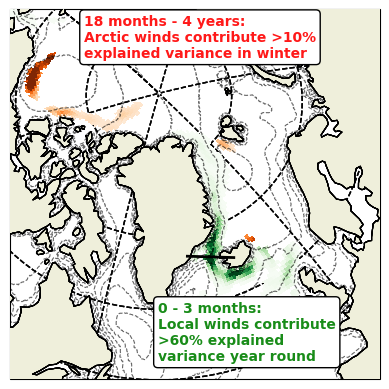

In [81]:
fig=plt.figure()
ilag=0
ev_plot=ev_2d[var].sel(lag=lag_labels[ilag]).mean('eyear')*1e12
conv_plot=(ds_plot_contr[var]/1e3).var('ym').mean('eyear').sel(lag_range=lag_labels[ilag])*1e3/(12*lag_lengths[ilag])
ds_plot=conv_plot.where(ev_plot>sig_ev)

[f,ax,p]=ut.plot_ecco(ecco_grid,ds_plot,
                    # cmin=-clims[var][ilag]*1e12,cmax=clims[var][ilag]*1e12,
                      cmin=0,cmax=10,
                     cmap='Greens',**proj_dict,rasterized=True,show_colorbar=False)

ilag=3
ev_plot=ev_2d[var].sel(lag=lag_labels[ilag]).mean('eyear')*1e12
conv_plot=(ds_plot_contr[var]/1e3).var('ym').mean('eyear').sel(lag_range=lag_labels[ilag])*1e3/(12*lag_lengths[ilag])
ds_plot=conv_plot.where(ev_plot>sig_ev)


[f,ax,p]=ut.plot_ecco(ecco_grid,ds_plot,
                    # cmin=-clims[var][ilag]*1e12,cmax=clims[var][ilag]*1e12,
                      cmin=0,cmax=0.005,
                     cmap='Oranges',**proj_dict,rasterized=True,ax=ax,show_colorbar=False)
#[f,ax,p]=ut.plot_ecco(ecco_grid,xr.where(masks['arct']>0,1,np.nan),alpha=0.2,colors='Reds',ax=ax,**proj_dict)
[f,ax,p]=ut.plot_ecco(ecco_grid,mean_ssh,ax=ax,
                                  plot_type='contour',colors='k',mapping_method='bin_average',
                                  cmap=None,negative_linestyles='dashed',linewidths=0.8,
                                  levels=np.arange(-1.4,0,0.10),show_colorbar=False,alpha=0.6,
                                  **proj_dict)
ax.plot([section_pt1[0],section_pt2[0]],[section_pt1[1],section_pt2[1]],
                 color='k', linewidth=2,transform=ccrs.PlateCarree(),zorder=1000)
ax.set_extent([xmin,xmax,ymin,ymax], crs=my_projn)
ax.text(0.2,0.87,f'18 months - 4 years:\nArctic winds contribute >10%\nexplained variance in winter',color='r',backgroundcolor='w',alpha=0.9,transform=ax.transAxes,
       bbox={'fc':'w','boxstyle':'round'},zorder=100,fontweight='bold')
ax.text(0.4,0.05,f'0 - 3 months:\nLocal winds contribute\n>60% explained\nvariance year round',color='g',backgroundcolor='w',alpha=0.9,transform=ax.transAxes,
       bbox={'fc':'w','boxstyle':'round'},zorder=100,fontweight='bold')
plt.savefig('../plots/summary.pdf')

In [15]:
masks=ut.load_canari_masks()
masks.keys()

get_basin_name:  ['atl'] /users/emmomp/Python/ECCOv4-py/binary_data
load_binary_array: loading file /users/emmomp/Python/ECCOv4-py/binary_data/basins.data
load_binary_array: data array shape  (1170, 90)
load_binary_array: data array type  >f4
llc_compact_to_faces: dims, llc  (1170, 90) 90
llc_compact_to_faces: data_compact array type  >f4
llc_faces_to_tiles: data_tiles shape  (13, 90, 90)
llc_faces_to_tiles: data_tiles dtype  >f4
shape after reading 
(13, 90, 90)
get_basin_name:  ['arct'] /users/emmomp/Python/ECCOv4-py/binary_data
load_binary_array: loading file /users/emmomp/Python/ECCOv4-py/binary_data/basins.data
load_binary_array: data array shape  (1170, 90)
load_binary_array: data array type  >f4
llc_compact_to_faces: dims, llc  (1170, 90) 90
llc_compact_to_faces: data_compact array type  >f4
llc_faces_to_tiles: data_tiles shape  (13, 90, 90)
llc_faces_to_tiles: data_tiles dtype  >f4
shape after reading 
(13, 90, 90)
get_basin_name:  ['hudson'] /users/emmomp/Python/ECCOv4-py/bina

dict_keys(['global', 'arct', 'hudson', 'med', 'north', 'baffin', 'barents', 'natl', 'satl', 'gland', 'norw'])

In [16]:
fc=ut.get_soln(FCNAME,DATA_DIR)
fc_climanom,fc_mth=ut.soln_anoms(fc)

read_llc_to_tiles: full_filename:  ../data_out/m_horflux_fw_denm.0000000129.data


In [17]:
ilag=0
ev_plot=ev_2d[var].sel(lag=lag_labels[ilag]).mean('eyear')*1e12
pred=ds_plot_contr.wind_OCE.sel(lag_range=lag_labels[ilag]).where(ev_plot>sig_ev).sum(['tile','j','i'])
ev=1-((fc_climanom-pred.swap_dims({'ym':'dates'}).rename({'dates':'time'})).var('time'))/fc_climanom.var('time')
ev_localwind=ev.mean().load()
ev_localwind_bym=1-(fc_mth-pred.unstack('ym')).var('year')/fc_mth.var('year')

In [18]:
ev_localwind_bym.mean('eyear').load()

<xarray.DataArray (month: 12)> Size: 96B
array([0.55844032, 0.75167979, 0.49914874, 0.89978951, 0.89784505,
       0.65722945, 0.65575454, 0.36448299, 0.6716616 , 0.70190913,
       0.67311225, 0.38248975])
Coordinates:
  * month      (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
    transp     <U2 8B 'fw'
    lag_range  <U16 64B '0 to -3m lag'
    TRANSP     <U2 8B 'fw'
    lag        <U16 64B '0 to -3m lag'

In [19]:
ilag=0
pred=ds_plot_contr.wind_OCE.sel(lag_range=lag_labels[ilag]).sum(['tile','j','i'])
ev=1-((fc_climanom-pred.swap_dims({'ym':'dates'}).rename({'dates':'time'})).var('time'))/fc_climanom.var('time')
ev_globalwind=ev.load().mean()
ev_globalwind_bym=1-(fc_mth-pred.unstack('ym')).var('year')/fc_mth.var('year')

In [24]:
ev_globalwind_bym.mean('eyear').load()

<xarray.DataArray (month: 12)> Size: 96B
array([0.67996974, 0.85943078, 0.68574813, 0.92384219, 0.83875624,
       0.79442623, 0.74610165, 0.48376578, 0.67814642, 0.72301045,
       0.64273608, 0.54427209])
Coordinates:
  * month      (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
    transp     <U2 8B 'fw'
    lag_range  <U16 64B '0 to -3m lag'
    TRANSP     <U2 8B 'fw'

In [20]:
ilag=0
ev_plot=ev_2d[var].sel(lag=lag_labels[ilag]).mean('eyear')*1e12
pred=ds_plot_contr.wind_OCE.sel(lag_range=lag_labels[ilag]).where(ev_plot<=sig_ev).sum(['tile','j','i'])
ev=1-((fc_climanom-pred.swap_dims({'ym':'dates'}).rename({'dates':'time'})).var('time'))/fc_climanom.var('time')
ev_nonlocalwind=ev.mean().load()
ev_nonlocalwind_bym=1-(fc_mth-pred.unstack('ym')).var('year')/fc_mth.var('year')

In [25]:
ev_nonlocalwind_bym.mean('eyear').load()

<xarray.DataArray (month: 12)> Size: 96B
array([-0.37717097, -0.25266563, -0.29972434, -0.20566785, -0.53528656,
       -0.29500101, -0.03963784, -0.12611987, -0.16292169, -0.18417983,
       -0.26100799, -0.39844919])
Coordinates:
  * month      (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
    transp     <U2 8B 'fw'
    lag_range  <U16 64B '0 to -3m lag'
    TRANSP     <U2 8B 'fw'
    lag        <U16 64B '0 to -3m lag'

In [27]:
(ev_globalwind_bym-ev_nonlocalwind_bym).mean('eyear').load()

<xarray.DataArray (month: 12)> Size: 96B
array([1.05714072, 1.1120964 , 0.98547248, 1.12951004, 1.3740428 ,
       1.08942725, 0.78573949, 0.60988565, 0.84106811, 0.90719029,
       0.90374407, 0.94272128])
Coordinates:
  * month      (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
    transp     <U2 8B 'fw'
    lag_range  <U16 64B '0 to -3m lag'
    TRANSP     <U2 8B 'fw'
    lag        <U16 64B '0 to -3m lag'

Text(0, 0.5, '%')

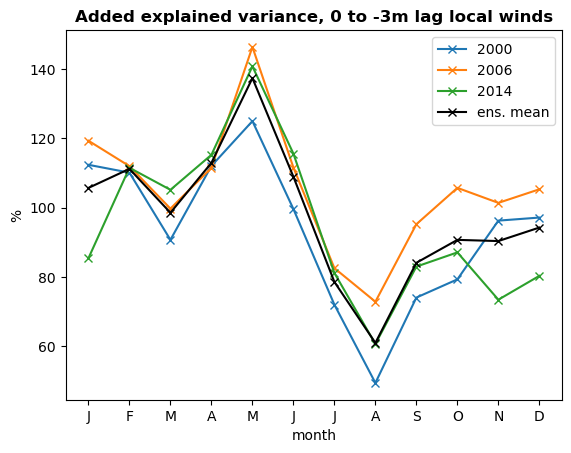

In [32]:
(100*(ev_globalwind_bym-ev_nonlocalwind_bym)).plot(x='month',hue='eyear',marker='x')
(100*(ev_globalwind_bym-ev_nonlocalwind_bym)).mean('eyear').plot(x='month',color='k',marker='x')
#plt.axhline(0,color='grey')
plt.xticks(np.arange(1,13),['J','F','M','A','M','J','J','A','S','O','N','D'])
plt.legend(['2000','2006','2014','ens. mean'])
plt.title('Added explained variance, 0 to -3m lag local winds',fontweight='bold')
#plt.text(6,10,'Adds Skill',fontsize=12,color='green')
#plt.text(2,-15,'Removes Skill',fontsize=12,color='red')
plt.ylabel('%')

Text(0, 0.5, '%')

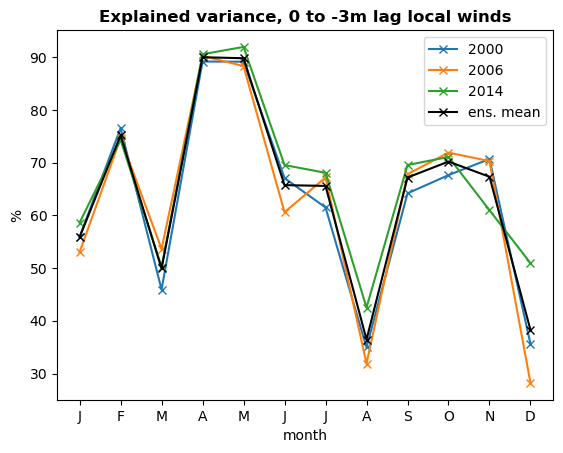

In [30]:
(100*ev_localwind_bym).plot(x='month',hue='eyear',marker='x')
(100*ev_localwind_bym).mean('eyear').plot(x='month',color='k',marker='x')
#plt.axhline(0,color='grey')
plt.xticks(np.arange(1,13),['J','F','M','A','M','J','J','A','S','O','N','D'])
plt.legend(['2000','2006','2014','ens. mean'])
plt.title('Explained variance, 0 to -3m lag local winds',fontweight='bold')
#plt.text(6,10,'Adds Skill',fontsize=12,color='green')
#plt.text(2,-15,'Removes Skill',fontsize=12,color='red')
plt.ylabel('%')

In [15]:
ilag=0
pred=ds_plot_contr.wind_OCE.sel(lag_range=lag_labels[ilag]).where(masks['gland']+masks['natl']).sum(['tile','j','i'])
ev=1-((fc_climanom-pred.swap_dims({'ym':'dates'}).rename({'dates':'time'})).var('time'))/fc_climanom.var('time')
ev_glandatlwind=ev.mean().load()

In [33]:
ilag=3
pred=ds_plot_contr.wind_OCE.sel(lag_range=lag_labels[ilag]).where(masks['arct']).sum(['tile','j','i'])
ev=1-((fc_climanom-pred.swap_dims({'ym':'dates'}).rename({'dates':'time'})).var('time'))/fc_climanom.var('time')
ev_arcticwind=ev.load().mean()

Text(0, 0.5, '%')

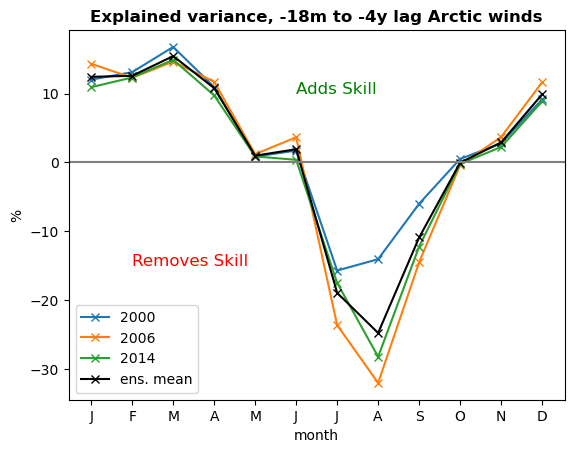

In [34]:
ev_arcticwind_bym=1-(fc_mth-pred.unstack('ym')).var('year')/fc_mth.var('year')
(100*ev_arcticwind_bym).plot(x='month',hue='eyear',marker='x')
(100*ev_arcticwind_bym).mean('eyear').plot(x='month',color='k',marker='x')
plt.axhline(0,color='grey')
plt.xticks(np.arange(1,13),['J','F','M','A','M','J','J','A','S','O','N','D'])
plt.legend(['2000','2006','2014','ens. mean'])
plt.title('Explained variance, -18m to -4y lag Arctic winds',fontweight='bold')
plt.text(6,10,'Adds Skill',fontsize=12,color='green')
plt.text(2,-15,'Removes Skill',fontsize=12,color='red')
plt.ylabel('%')

In [35]:
ilag=3
pred=ds_plot_contr.wind_OCE.sel(lag_range=lag_labels[ilag]).where(masks['arct']==0).sum(['tile','j','i'])
ev=1-((fc_climanom-pred.swap_dims({'ym':'dates'}).rename({'dates':'time'})).var('time'))/fc_climanom.var('time')
ev_gmarcticwind=ev.load().mean()
ev_gmarcticwind_bym=1-(fc_mth-pred.unstack('ym')).var('year')/fc_mth.var('year')

In [36]:
ilag=3
pred=ds_plot_contr.wind_OCE.sel(lag_range=lag_labels[ilag]).sum(['tile','j','i'])
ev=1-((fc_climanom-pred.swap_dims({'ym':'dates'}).rename({'dates':'time'})).var('time'))/fc_climanom.var('time')
ev_globalwind=ev.load().mean()
ev_globalwind_bym=1-(fc_mth-pred.unstack('ym')).var('year')/fc_mth.var('year')

In [37]:
ev_globalwind-ev_gmarcticwind

<xarray.DataArray ()> Size: 8B
array(0.06044518)
Coordinates:
    transp     <U2 8B 'fw'
    lag_range  <U16 64B '-18m to -4 y lag'
    TRANSP     <U2 8B 'fw'
    k          int64 8B 0
    Z          float32 4B -5.0
    drF        float32 4B 10.0
    PHrefC     float32 4B 49.05

Text(0, 0.5, '%')

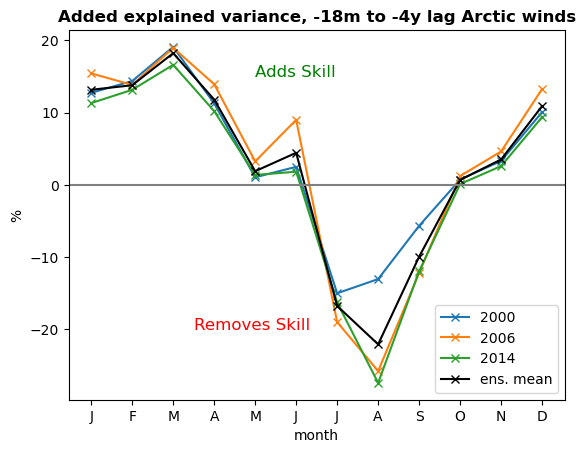

In [40]:
#ev_arcticwind_bym=1-(fc_mth-pred.unstack('ym')).var('year')/fc_mth.var('year')
(100*(ev_globalwind_bym-ev_gmarcticwind_bym)).plot(x='month',hue='eyear',marker='x')
(100*(ev_globalwind_bym-ev_gmarcticwind_bym)).mean('eyear').plot(x='month',color='k',marker='x')
plt.axhline(0,color='grey')
plt.xticks(np.arange(1,13),['J','F','M','A','M','J','J','A','S','O','N','D'])
plt.legend(['2000','2006','2014','ens. mean'])
plt.title('Added explained variance, -18m to -4y lag Arctic winds',fontweight='bold')
plt.text(5,15,'Adds Skill',fontsize=12,color='green')
plt.text(3.5,-20,'Removes Skill',fontsize=12,color='red')
plt.ylabel('%')

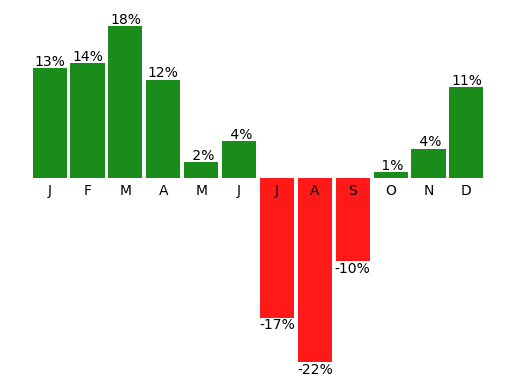

In [79]:
bb=plt.bar(np.arange(1,13),(100*(ev_globalwind_bym-ev_gmarcticwind_bym)).mean('eyear').data.compute(),
           color=['g','g','g','g','g','g','r','r','r','g','g','g'],
           alpha=0.9,width=0.9)
plt.bar_label(bb,fmt='{:2.0f}%')
plt.xticks(np.arange(1,13),['J','F','M','A','M','J','J','A','S','O','N','D'])
ax.set_xticklabels(ax.get_xticks(),fontweight='bold',fontsize=12,color='b')
ax=plt.gca()
ax.xaxis.set_tick_params(length=0)
ax.spines['bottom'].set_position('zero')
plt.ylabel('')
#plt.axis('off')
plt.tick_params(left=False)
plt.yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
#ax.get_xticklabels()

In [75]:
ax.set_xticklabels?

Signature: ax.set_xticklabels(labels, *, minor=False, fontdict=None, **kwargs)
Docstring:
[*Discouraged*] Set the xaxis' tick labels with list of string labels.

.. admonition:: Discouraged

    The use of this method is discouraged, because of the dependency on
    tick positions. In most cases, you'll want to use
    ``Axes.set_[x/y/z]ticks(positions, labels)`` or ``Axes.set_xticks``
    instead.

    If you are using this method, you should always fix the tick
    positions before, e.g. by using `.Axes.set_xticks` or by explicitly
    setting a `~.ticker.FixedLocator`. Otherwise, ticks are free to
    move and the labels may end up in unexpected positions.

Parameters
----------
labels : sequence of str or of `.Text`\s
    Texts for labeling each tick location in the sequence set by
    `.Axes.set_xticks`; the number of labels must match the number of locations.
    The labels are used as is, via a `.FixedFormatter` (without further
    formatting).

minor : bool
    If True, set mi

In [54]:
fc_lo=ut.butter_ufunc(fc_climanom,13,'time')
pred_lo=ut.butter_ufunc(pred.swap_dims({'ym':'dates'}).rename({'dates':'time'}),13,'time')
ev=1-((fc_lo-pred_lo).var('time'))/fc_lo.var('time')
ev_arctwind_lo=ev.mean().load()

In [48]:
ilag=3
ev_plot=ev_2d[var].sel(lag=lag_labels[ilag]).mean('eyear')*1e12
pred=ds_plot_contr.wind_OCE.sel(lag_range=lag_labels[ilag]).where(ev_plot>sig_ev).sum(['tile','j','i'])
ev=1-((fc_climanom-pred.swap_dims({'ym':'dates'}).rename({'dates':'time'})).var('time'))/fc_climanom.var('time')
ev_bfortwind=ev.load().mean()

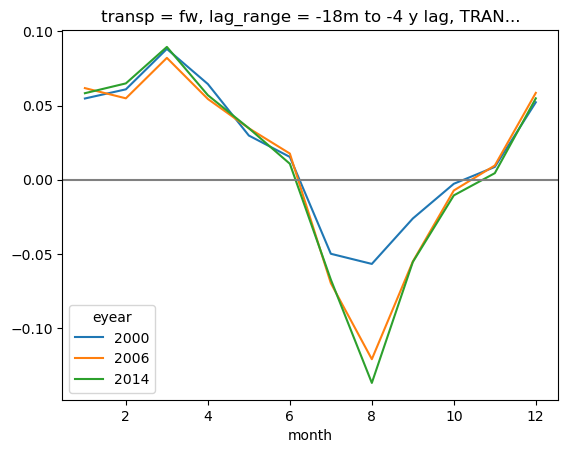

In [49]:
ev_bfortwind_bym=1-(fc_mth-pred.unstack('ym')).var('year')/fc_mth.var('year')
ev_bfortwind_bym.plot(x='month',hue='eyear')
plt.axhline(0,color='grey')

In [56]:
fc_lo=ut.butter_ufunc(fc_climanom,13,'time')
pred_lo=ut.butter_ufunc(pred.swap_dims({'ym':'dates'}).rename({'dates':'time'}),13,'time')
ev=1-((fc_lo-pred_lo).var('time'))/fc_lo.var('time')
ev_bfortwind_lo=ev.mean().load()

In [60]:
for stat in [ev_localwind,ev_glandatlwind,ev_arctwind_lo,ev_bfortwind_lo]:
    print(f"{stat.data:2.2f}")

0.64
0.68
0.13
0.07
